# BERT 복습과제: 마스킹으로 깊은 양방향 문맥 학습하기
**논문:** Devlin et al., *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*, NAACL 2019 (첨부 자료: arXiv v2)

이 과제에서는 BERT의 입력 표현과 모델 크기를 직접 계산하고 사전학습 데이터를 만드는 MLM 마스킹·NSP 규칙을 구현합니다. 이어서 양방향/단방향 self-attention의 차이를 확인하고 작은 인코더를 직접 사전학습해 비교한 뒤 [CLS] 분류와 SQuAD 구간 예측 헤드를 만듭니다.

| 파트 | 실습 | 논문 연결 |
|---|---|---|
| 1 | 입력 표현과 모델 크기 | §3 (Figure 2, BERT-BASE/LARGE) |
| 2 | MLM 마스킹(80/10/10)과 NSP 쌍 만들기 | §3.1 |
| 3 | 양방향 vs 단방향 self-attention | §3, Figure 3 (부록 A.4) |
| 4 | 작은 인코더 사전학습: 양방향 vs 단방향 | §5.1, Table 5 |
| 5 | fine-tuning 헤드: [CLS] 분류, 구간 예측 | §3.2, §4.2–4.3 |
| 6 | 결과 해석과 서술형 | §5–6 |

**진행 방법**
- Colab의 **파일 → 노트북 업로드**에서 이 파일을 열고 위에서부터 차례로 실행하세요. 기본 CPU 런타임으로 충분하며 GPU는 필요 없습니다. 내려받는 데이터나 모델도 없습니다.
- `________`를 TODO 번호(①~⑳)와 힌트에 맞춰 바꾸세요. 빈칸 뒤의 **✅ 확인 셀**이 통과하면 구현의 성질이 맞는 것입니다.
- 예상 학습 시간은 약 60~80분입니다. Part 4의 실험 실행에는 약 1분이 따로 걸립니다.
- 코드, 실행 결과, 서술형 답을 남긴 `.ipynb`를 제출하세요. (파일명 · PR 제목 · 라벨 · 브랜치 규칙은 기존 복습과제와 동일)

In [1]:
# 0. 환경 설정: Colab 기본 PyTorch만 사용합니다.
import math, copy, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_everything()

# 0~3은 특수 토큰, 4번부터는 일반 토큰입니다.
PAD, CLS, SEP, MASK = 0, 1, 2, 3
N_SPECIAL = 4
print('torch:', torch.__version__)

torch: 2.14.1+cpu


## Part 1. 입력 표현과 모델 크기 (§3, Figure 2)
BERT의 입력은 토큰 시퀀스 하나입니다. 문장 쌍은 `[CLS] A [SEP] B [SEP]` 순서로 이어 붙이고, 각 토큰에 **토큰 + 세그먼트 + 위치** embedding을 더합니다. 문장 A에 속한 토큰(첫 번째 `[SEP]` 포함)의 segment id는 0, 문장 B에 속한 토큰(마지막 `[SEP]` 포함)은 1입니다. 이 과제에서 패딩은 segment 0으로 둡니다.

### 문제 1-1. 문장 쌍 입력 만들기

In [2]:
def build_pair_input(tokens_a, tokens_b=None, max_len=16):
    ids = [CLS] + tokens_a + [SEP]
    segs = [0] * len(ids)                          # [CLS] A [SEP]은 segment 0
    if tokens_b is not None:
        ids += tokens_b + [SEP]  # TODO ①: B와 마지막 [SEP]을 이어 붙이기
        segs += [1] * (len(tokens_b) + 1)  # TODO ②: B와 마지막 [SEP]의 segment id → len(B) + 1개
    n_pad = max_len - len(ids)
    attn = [1] * len(ids) + [0] * n_pad            # 실제 토큰 1, 패딩 0
    ids += [PAD] * n_pad
    segs += [0] * n_pad
    return ids, segs, attn

In [3]:
# ✅ 확인 셀
ids, segs, attn = build_pair_input([10, 11], [12, 13, 14], max_len=12)
assert ids == [CLS, 10, 11, SEP, 12, 13, 14, SEP, PAD, PAD, PAD, PAD]
assert segs == [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0]
assert attn == [1] * 8 + [0] * 4
ids1, segs1, attn1 = build_pair_input([10, 11, 12], None, max_len=8)
assert ids1 == [CLS, 10, 11, 12, SEP, PAD, PAD, PAD] and segs1 == [0] * 8
print('ids :', ids)
print('segs:', segs)
print('✅ [CLS] A [SEP] B [SEP] 구성과 segment id 확인')

ids : [1, 10, 11, 2, 12, 13, 14, 2, 0, 0, 0, 0]
segs: [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0]
✅ [CLS] A [SEP] B [SEP] 구성과 segment id 확인


### 문제 1-2. 세 embedding의 합으로 입력 표현 만들기
Figure 2처럼 토큰, 세그먼트, 위치 embedding을 **더합니다**. 위치 embedding은 사인/코사인 고정값이 아니라 학습되는 embedding이며 마지막에 LayerNorm을 적용합니다.

In [4]:
class BertEmbeddings(nn.Module):
    def __init__(self, vocab_size, hidden, max_len=512):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, hidden)
        self.seg = nn.Embedding(2, hidden)
        self.pos = nn.Embedding(max_len, hidden)
        self.ln = nn.LayerNorm(hidden)

    def forward(self, ids, segs):
        positions = torch.arange(ids.size(1), device=ids.device).unsqueeze(0)   # [1, L]
        x = self.tok(ids) + self.seg(segs) + self.pos(positions)  # TODO ③: 세 embedding 더하기
        return self.ln(x)

In [5]:
# ✅ 확인 셀
seed_everything(0)
emb = BertEmbeddings(vocab_size=50, hidden=16, max_len=32)
ids = torch.tensor([[CLS, 10, 11, SEP, 12, SEP]])
segs = torch.tensor([[0, 0, 0, 0, 1, 1]])
out = emb(ids, segs)
assert out.shape == (1, 6, 16)

same_tok = torch.tensor([[10, 10]])      # 같은 토큰이라도 위치가 다르면 표현이 달라야 합니다.
o = emb(same_tok, torch.zeros_like(same_tok))
assert not torch.allclose(o[0, 0], o[0, 1])

assert not torch.allclose(out[0, 4], emb(ids, torch.zeros_like(segs))[0, 4])   # segment가 다르면 표현도 다릅니다.

pre = emb.tok(ids) + emb.seg(segs) + emb.pos(torch.arange(6).unsqueeze(0))
torch.testing.assert_close(out, emb.ln(pre))    # LayerNorm 직전 값 = 세 embedding의 합
print('✅ 토큰 + 세그먼트 + 위치 embedding 확인')

✅ 토큰 + 세그먼트 + 위치 embedding 확인


### 문제 1-3. BERT-BASE / BERT-LARGE 파라미터 수 계산하기
$L$은 층 수, $H$는 hidden size, feed-forward 크기는 항상 $4H$입니다 (§3). 어휘 크기 $V=30{,}000$, 최대 길이 $P=512$로 계산하며 다음을 모두 포함합니다.

- **embedding:** 토큰 $VH$, 위치 $PH$, 세그먼트 $2H$, LayerNorm의 $\gamma,\beta$ $2H$
- **self-attention:** Q, K, V, 출력 투영 4개, 각각 $H\times H$ 가중치와 $H$ bias
- **feed-forward:** 선형층 2개 ($H\to4H\to H$), bias 포함
- **LayerNorm:** 층마다 2개, 각각 $\gamma,\beta$
- **pooler:** $H\times H$ 가중치와 bias (공개 구현에 있는 [CLS]용 층)

MLM·NSP 출력층은 제외합니다.

In [6]:
def bert_param_count(L, H, V=30_000, P=512):
    FF = 4 * H
    embed = V * H + P * H + 2 * H + 2 * H  # TODO ④: embedding 3종 + LayerNorm = H(V + P + 4)
    attn = 4 * (H * H + H)  # TODO ⑤: Q, K, V, 출력 투영 (가중치 + bias)
    ffn = (H * FF + FF) + (FF * H + H)  # TODO ⑥: 선형층 2개 (가중치 + bias)
    ln = 2 * (2 * H)                                       # 층마다 LayerNorm 2개 × (γ, β)
    pooler = H * H + H
    per_layer = attn + ffn + ln
    return embed, per_layer, pooler, embed + L * per_layer + pooler

In [7]:
# ✅ 확인 셀
eB, per_layer, _, total_base = bert_param_count(12, 768)
eL, _, _, total_large = bert_param_count(24, 1024)
assert eB == 23_436_288 and per_layer == 7_087_872

# PyTorch의 TransformerEncoderLayer와 층당 파라미터 수가 같아야 합니다.
layer = nn.TransformerEncoderLayer(768, 12, 3072, batch_first=True)
assert sum(p.numel() for p in layer.parameters()) == per_layer

print(f'BERT-BASE  계산값 {total_base / 1e6:.1f}M (논문 표기 110M)')
print(f'BERT-LARGE 계산값 {total_large / 1e6:.1f}M (논문 표기 340M)')
print(f'embedding 비중: BASE {eB / total_base:.1%}, LARGE {eL / total_large:.1%}')
assert 0.97 < total_base / 110e6 < 1.01 and 0.97 < total_large / 340e6 < 1.01
print('✅ 파라미터 수 확인')

BERT-BASE  계산값 109.1M (논문 표기 110M)
BERT-LARGE 계산값 334.6M (논문 표기 340M)
embedding 비중: BASE 21.5%, LARGE 9.3%
✅ 파라미터 수 확인


In [8]:
# (추가) 공개된 uncased 모델의 실제 vocab 크기(30,522)로도 계산해봄
for name, (L, H) in {'BASE': (12, 768), 'LARGE': (24, 1024)}.items():
    print(name, f'{bert_param_count(L, H, V=30_522)[-1] / 1e6:.1f}M')

BASE 109.5M
LARGE 335.1M


**1-4.** 위 출력의 embedding 비중을 BASE와 LARGE에서 비교하고, 모델이 커질수록 비중이 어떻게 변하는지 이유와 함께 쓰세요. 계산값과 논문 표기(110M, 340M)가 조금 다른 것은 이 과제의 계산으로 설명할 수 있나요?

**답변:**

- 출력값 기준 embedding 비중은 BASE 21.5%, LARGE 9.3%로 모델이 커질수록 비중이 확 줄어든다.
- embedding 파라미터는 $H(V+P+4)$라서 $H$에 **선형**으로만 늘어나는데, encoder 한 층은 대략 $12H^2$라서 $H$에 대해 **제곱**으로 늘고 거기에 층 수 $L$까지 곱해진다.
  - BASE → LARGE: $H$ 768 → 1024 (1.33배), $L$ 12 → 24 (2배)
  - embedding은 23.4M → 31.2M (1.33배)인데 encoder 전체는 85.1M → 302.3M (약 3.6배)
  - 그래서 모델이 커질수록 전체에서 embedding이 차지하는 비율이 작아짐
- 논문 표기와의 차이: 계산값이 BASE 109.1M, LARGE 334.6M으로 110M / 340M보다 조금 작다. 이 과제 계산만으로 딱 맞게 설명되지는 않고, 논문 숫자 자체가 반올림한 대략적인 값이라고 보는 게 맞는 것 같다.
  - 이 계산은 $V=30{,}000$으로 잡았고 MLM·NSP 출력층은 뺐다. 공개된 uncased 모델의 실제 vocab 크기(30,522)로 다시 계산해 봐도 BASE 109.5M, LARGE 335.1M이라(아래 추가 셀) BASE는 거의 맞고 LARGE는 여전히 5M 정도 차이 남 → LARGE는 논문에서 넉넉하게 반올림한 듯.

## Part 2. 사전학습 데이터 만들기: MLM과 NSP (§3.1)
### 문제 2-1. 마스킹 80/10/10 규칙 구현하기
각 시퀀스에서 WordPiece 토큰의 15%를 예측 대상으로 고르고 고른 토큰을 다음과 같이 바꿉니다.

| 확률 | 처리 |
|---|---|
| 80% | `[MASK]`로 교체 |
| 10% | 무작위 토큰으로 교체 |
| 10% | 원래 토큰 유지 |

모델은 **고른 위치에서만** 원래 토큰을 예측합니다. 나머지 위치의 label은 `-100`으로 두어 loss에서 무시합니다. `[CLS]`, `[SEP]`, `[PAD]`는 고르지 않습니다.

In [9]:
def mask_tokens(ids, vocab_size, mlm_prob=0.15, generator=None):
    # ids: [B, L]. 반환: (모델 입력, label). label은 예측 대상이 아닌 위치에서 -100
    inputs, labels = ids.clone(), ids.clone()
    special = ids < N_SPECIAL                                  # [PAD], [CLS], [SEP], [MASK]는 마스킹하지 않음
    prob = torch.full(ids.shape, mlm_prob).masked_fill(special, 0.0)
    selected = torch.bernoulli(prob, generator=generator).bool()  # TODO ⑦: 확률 prob로 예측 대상 고르기 (bernoulli)
    labels[~selected] = -100                                   # loss는 고른 위치에서만 계산

    r = torch.rand(ids.shape, generator=generator)             # 고른 토큰을 어떻게 바꿀지 정하는 난수
    to_mask = selected & (r < 0.8)  # TODO ⑧: 고른 것의 80% → [MASK]
    to_rand = selected & (r >= 0.8) & (r < 0.9)  # TODO ⑨: 고른 것의 10% → 무작위 토큰 (0.8 <= r < 0.9 구간)
    inputs[to_mask] = MASK
    random_tokens = torch.randint(N_SPECIAL, vocab_size, ids.shape, generator=generator)
    inputs[to_rand] = random_tokens[to_rand]
    # 남은 10%는 원래 토큰을 그대로 둡니다.
    return inputs, labels

In [10]:
# ✅ 확인 셀: 큰 표본에서 비율을 확인합니다.
g = torch.Generator().manual_seed(0)
B, L, V = 4000, 64, 100
ids = torch.randint(N_SPECIAL, V, (B, L), generator=g)
ids[:, 0] = CLS; ids[:, -1] = SEP; ids[:, 5] = PAD
inputs, labels = mask_tokens(ids, V, generator=g)

special = ids < N_SPECIAL
sel = labels != -100
assert not (sel & special).any(), '특수 토큰은 고르면 안 됩니다.'
assert (inputs[special] == ids[special]).all()
assert (labels[sel] == ids[sel]).all(), 'label에는 원래 토큰이 들어가야 합니다.'
assert (inputs[~sel] == ids[~sel]).all(), '고르지 않은 위치는 바뀌면 안 됩니다.'

r_sel = sel.sum().item() / (~special).sum().item()
si, so = inputs[sel], ids[sel]
r_mask = (si == MASK).float().mean().item()
r_keep = (si == so).float().mean().item()
r_rand = ((si != MASK) & (si != so)).float().mean().item()
print(f'선택 비율 {r_sel:.3f} | [MASK] {r_mask:.3f} | 그대로 {r_keep:.3f} | 무작위 {r_rand:.3f}')
assert abs(r_sel - 0.15) < 0.01
assert abs(r_mask - 0.80) < 0.01 and abs(r_keep - 0.10) < 0.01 and abs(r_rand - 0.10) < 0.01
print('✅ 15% 선택, 80/10/10 처리 확인')

선택 비율 0.150 | [MASK] 0.801 | 그대로 0.101 | 무작위 0.098
✅ 15% 선택, 80/10/10 처리 확인


**2-2.** 고른 토큰을 항상 `[MASK]`로만 바꾸면 어떤 문제가 생기나요? 논문(§3.1)은 이를 어떻게 완화하며, 위 `mask_tokens`의 어느 부분이 그 역할을 하나요?

**답변:**

- 항상 `[MASK]`로만 바꾸면 pre-training 입력에는 `[MASK]`가 계속 나오는데 fine-tuning 때는 `[MASK]`가 아예 안 나오니까 **pre-training과 fine-tuning 사이에 mismatch**가 생긴다.
- 또 모델 입장에서는 "`[MASK]` 자리만 맞히면 된다"는 걸 알게 돼서, `[MASK]`가 아닌 토큰은 문맥을 반영한 표현을 굳이 잘 만들 필요가 없어짐.
- 논문(§3.1, 부록 A.1)은 고른 15% 중 **80%만 `[MASK]`, 10%는 무작위 토큰, 10%는 그대로** 둬서 이걸 완화한다. 이러면 모델은 어떤 토큰이 예측 대상인지, 어떤 게 무작위로 바뀐 건지 모르니까 모든 입력 토큰에 대해 문맥 표현을 유지해야 함. 무작위로 바뀌는 건 전체 토큰의 1.5%(15% × 10%)뿐이라 언어 이해를 크게 해치지 않는다고 한다.
- 코드에서는 `to_rand`(r이 0.8~0.9 구간이면 무작위 토큰)랑, `to_mask`/`to_rand` 어디에도 안 걸린 나머지 10%(원래 토큰 유지)가 이 역할을 한다.
  - 무작위 토큰이 우연히 원래 토큰과 같을 수도 있어서(확인 셀 기준 1/96) 엄밀히는 '그대로' 기대값이 0.1보다 아주 조금 크다.

### 문제 2-3. NSP 학습 쌍 만들기
사전학습 예시마다 문장 A와 B를 고릅니다. 50%는 B가 실제로 A 다음에 오는 문장(`IsNext`, label 1), 50%는 무작위 문장(`NotNext`, label 0)입니다. 논문은 코퍼스에서 무작위로 뽑지만 이 과제에서는 우연히 진짜 다음 문장이 뽑히지 않도록 **다른 문서**에서 뽑습니다.

In [11]:
def make_nsp_pairs(docs, rng):
    # docs: 문서 리스트. 문서는 문장 리스트, 문장은 토큰 id 리스트
    pairs = []
    for d_i, doc in enumerate(docs):
        for s_i in range(len(doc) - 1):
            a = doc[s_i]
            if rng.random() < 0.5:
                b, label = doc[s_i + 1], 1  # TODO ⑩: IsNext (바로 다음 문장)
            else:
                other = rng.choice([j for j in range(len(docs)) if j != d_i])
                b, label = docs[other][rng.integers(len(docs[other]))], 0  # TODO ⑪: NotNext (다른 문서의 무작위 문장) ※ rng.choice(docs[other])는 문장 길이가 다르면 에러 나서 인덱스로 뽑음
            pairs.append((a, b, label))
    return pairs

In [12]:
# ✅ 확인 셀: 문장 하나를 [문서번호*100 + 문장번호] 토큰 하나로 표현해 검사합니다.
rng = np.random.default_rng(0)
docs = [[[d * 100 + s] for s in range(10)] for d in range(50)]
pairs = make_nsp_pairs(docs, rng)
assert len(pairs) == 50 * 9
y = np.array([p[2] for p in pairs])
print('IsNext 비율:', y.mean().round(3))
assert 0.42 < y.mean() < 0.58
for a, b, label in pairs:
    da, sa = divmod(int(a[0]), 100); db, sb = divmod(int(b[0]), 100)
    if label == 1:
        assert (db, sb) == (da, sa + 1), 'IsNext는 같은 문서의 바로 다음 문장이어야 합니다.'
    else:
        assert db != da, 'NotNext는 다른 문서에서 뽑아야 합니다.'
print('✅ IsNext / NotNext 구성 확인')

IsNext 비율: 0.453
✅ IsNext / NotNext 구성 확인


## Part 3. 양방향 vs 단방향 self-attention (§3, Figure 3)
BERT-BASE와 OpenAI GPT는 모델 크기가 같고 결정적인 차이는 self-attention이 보는 범위입니다. BERT는 모든 위치를 보고 GPT는 자기 **왼쪽(자신 포함)** 만 봅니다. 아래는 head 하나짜리 self-attention입니다.

$$\mathrm{scores}=\frac{QK^\top}{\sqrt d},\qquad \mathrm{out}=\mathrm{softmax}(\mathrm{scores})\,V$$

### 문제 3-1. 단방향 마스크 만들기
`causal=True`이면 위치 $i$는 $j\le i$인 위치만 볼 수 있어야 합니다. 볼 수 없는 칸의 점수를 $-\infty$로 만들면 softmax 뒤 가중치가 0이 됩니다.

In [13]:
class SelfAttention(nn.Module):
    def __init__(self, d, causal=False):
        super().__init__()
        self.q, self.k, self.v, self.o = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.d, self.causal = d, causal

    def forward(self, x):
        # x: [B, L, d]
        q, k, v = self.q(x), self.k(x), self.v(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d)         # [B, L, L]
        if self.causal:
            L = x.size(1)
            allowed = torch.tril(torch.ones(L, L, dtype=torch.bool, device=x.device))  # TODO ⑫: j <= i인 칸만 True → 하삼각
            scores = scores.masked_fill(~allowed, float('-inf'))  # TODO ⑬: 볼 수 없는 칸을 -inf로
        w = scores.softmax(dim=-1)
        return self.o(w @ v), w

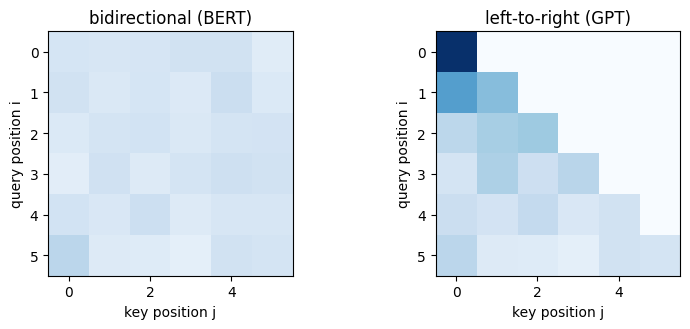

✅ 양방향은 전체를, 단방향은 왼쪽만 봅니다.


In [14]:
# ✅ 확인 셀: 같은 가중치로 양방향/단방향을 비교합니다.
seed_everything(0)
bi, uni = SelfAttention(16, causal=False), SelfAttention(16, causal=True)
uni.load_state_dict(bi.state_dict())
x = torch.randn(1, 6, 16)
x2 = x.clone(); x2[0, 5] += 1.0          # 맨 마지막(미래) 토큰만 바꿉니다.

y_bi, w_bi = bi(x);   y_bi2, _ = bi(x2)
y_uni, w_uni = uni(x); y_uni2, _ = uni(x2)

assert not torch.allclose(y_bi[0, 0], y_bi2[0, 0], atol=1e-6), '양방향이면 첫 위치도 미래 토큰의 영향을 받아야 합니다.'
torch.testing.assert_close(y_uni[0, :5], y_uni2[0, :5])                  # 단방향이면 앞쪽 위치는 그대로
assert not torch.allclose(y_uni[0, 5], y_uni2[0, 5])                     # 바뀐 위치 자신은 달라짐
assert torch.triu(w_uni[0], diagonal=1).abs().sum() == 0                 # 미래 위치 가중치는 0
assert (w_bi[0] > 0).all()

fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, w, title in [(axes[0], w_bi[0], 'bidirectional (BERT)'), (axes[1], w_uni[0], 'left-to-right (GPT)')]:
    ax.imshow(w.detach(), cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title); ax.set_xlabel('key position j'); ax.set_ylabel('query position i')
plt.tight_layout(); plt.show()
print('✅ 양방향은 전체를, 단방향은 왼쪽만 봅니다.')

**3-2.** 양방향 self-attention을 그대로 쓰면서 표준 언어 모델 목적(다음 단어 예측)으로 학습하면 왜 안 되나요? 위 `SelfAttention(causal=False)`의 동작과 연결해 설명하고, 논문이 대신 택한 방법을 쓰세요.

**답변:**

- 다음 단어 예측은 위치 $i$에서 $x_{i+1}$을 맞히는 건데, 양방향 attention이면 위치 $i$가 $i+1$(정답) 위치를 그대로 볼 수 있다. 위 확인 셀에서도 `w_bi`는 모든 칸이 0보다 컸고, 마지막(미래) 토큰만 바꿔도 첫 번째 위치 출력이 달라졌다 → 미래 정보가 전부 섞여 들어온다는 뜻.
- 그러면 정답이 이미 입력에 있으니 옆 위치를 복사하기만 하면 되고, 층을 여러 개 쌓으면 각 단어가 간접적으로 "자기 자신을 보게" 돼서 예측이 trivial해짐 → 의미 있는 학습이 안 된다. (GPT는 그래서 causal mask로 왼쪽만 보게 함)
- 논문은 양방향 구조는 그대로 두고 목적함수를 **Masked LM(Cloze task)** 으로 바꿨다. 입력 토큰 일부(15%)를 가리고 가린 위치의 원래 토큰만 예측하니까 정답이 입력에 없어서 양방향 attention을 써도 정답이 새지 않는다.

## Part 4. 작은 인코더를 직접 사전학습하기: 양방향 vs 단방향 (§5.1, Table 5의 축소판)
논문 §5.1은 같은 데이터와 설정에서 BERT식(MLM, 양방향)과 left-to-right(LTR) 모델을 비교합니다. 여기서는 그 구조만 작은 모델로 옮깁니다.

**데이터.** 숫자 9개 $s_1\dots s_9$ 앞뒤에 `[CLS]`, `[SEP]`를 붙입니다. $s_2,s_4,s_6,s_8$은 양옆 이웃의 합을 10으로 나눈 나머지($s_2=(s_1+s_3)\bmod 10$)이고, 나머지 자리는 무작위입니다. 평가는 $s_2,s_4,s_6,s_8$ 중 하나를 `[MASK]`로 가리고 맞히는 정확도이며 이를 맞히려면 **왼쪽과 오른쪽 이웃이 모두** 필요합니다. 아무것도 모르고 찍으면 10%입니다.

In [15]:
DIGIT0, N_DIGIT, SEQ = 4, 10, 9          # 숫자 d는 토큰 id DIGIT0 + d
VOCAB = DIGIT0 + N_DIGIT

def make_toy_batch(n, g):
    s = torch.randint(0, N_DIGIT, (n, SEQ), generator=g)
    for i in range(1, SEQ - 1, 2):                       # s2, s4, s6, s8 (0부터 세면 1, 3, 5, 7번째)
        s[:, i] = (s[:, i - 1] + s[:, i + 1]) % N_DIGIT
    return torch.cat([torch.full((n, 1), CLS), s + DIGIT0, torch.full((n, 1), SEP)], dim=1)

g = torch.Generator().manual_seed(0)
batch = make_toy_batch(4, g)
s = batch[:, 1:-1] - DIGIT0
for i in (1, 3, 5, 7):
    assert (s[:, i] == (s[:, i - 1] + s[:, i + 1]) % N_DIGIT).all()
print(batch[:2])

tensor([[ 1,  8, 11,  7, 10,  7,  4, 11,  8, 11,  2],
        [ 1,  7, 13, 10,  9, 13,  9, 10,  8, 12,  2]])


### 문제 4-1. 양방향/단방향 인코더 만들기
Part 1의 `BertEmbeddings`와 PyTorch의 `nn.TransformerEncoder`를 씁니다. `causal=True`이면 Part 3과 같은 왼쪽만 보는 마스크를 `mask=`로 넘깁니다. `nn.Transformer.generate_square_subsequent_mask(L)`은 볼 수 없는 칸이 $-\infty$인 $L\times L$ 마스크를 만들어 줍니다.

In [16]:
class TinyBERT(nn.Module):
    def __init__(self, vocab_size, d=64, layers=2, heads=4, max_len=16, causal=False):
        super().__init__()
        self.emb = BertEmbeddings(vocab_size, d, max_len)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, activation='gelu', batch_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, vocab_size)           # MLM 출력층: 각 위치의 hidden → 어휘 점수
        self.causal = causal

    def encode(self, ids, segs=None):
        if segs is None:
            segs = torch.zeros_like(ids)
        mask = nn.Transformer.generate_square_subsequent_mask(ids.size(1)).to(ids.device) if self.causal else None  # TODO ⑭: causal일 때만 미래 칸이 -inf인 마스크
        return self.enc(self.emb(ids, segs), mask=mask)       # [B, L, d]

    def forward(self, ids, segs=None):
        return self.head(self.encode(ids, segs))              # [B, L, vocab]

In [17]:
# ✅ 확인 셀: 같은 가중치에서 뒤쪽 토큰만 바꿨을 때 앞쪽 위치의 표현이 변하는지 확인합니다.
seed_everything(0)
m_bi, m_uni = TinyBERT(VOCAB, causal=False), TinyBERT(VOCAB, causal=True)
m_uni.load_state_dict(m_bi.state_dict())
m_bi.eval(); m_uni.eval()
x = make_toy_batch(2, torch.Generator().manual_seed(1))
x2 = x.clone(); x2[:, -2] = (x2[:, -2] - DIGIT0 + 1) % N_DIGIT + DIGIT0     # 마지막 숫자 토큰만 변경
with torch.no_grad():
    h_bi, h_bi2 = m_bi.encode(x), m_bi.encode(x2)
    h_uni, h_uni2 = m_uni.encode(x), m_uni.encode(x2)
assert not torch.allclose(h_bi[:, 1], h_bi2[:, 1], atol=1e-6), '양방향은 뒤쪽 변화가 앞쪽 표현에 영향을 줘야 합니다.'
torch.testing.assert_close(h_uni[:, :-2], h_uni2[:, :-2], atol=1e-5, rtol=1e-4)   # 단방향은 앞쪽이 그대로
print('✅ causal 마스크가 단방향 모델에만 적용됩니다.')

✅ causal 마스크가 단방향 모델에만 적용됩니다.


### 문제 4-2. MLM 사전학습 루프 완성하기
Part 2의 `mask_tokens`로 입력을 만들고, **고른 위치에서만** loss를 계산합니다. 데이터는 학습 신호가 적어 마스킹 확률을 15%보다 높은 30%로 둡니다.

In [18]:
def pretrain(model, steps=1500, bs=128, lr=3e-3, mlm_prob=0.3, seed=0):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    model.train()
    for step in range(steps):
        ids = make_toy_batch(bs, g)
        inputs, labels = mask_tokens(ids, VOCAB, mlm_prob=mlm_prob, generator=g)
        logits = model(inputs)                                              # [B, L, vocab]
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1), ignore_index=-100)  # TODO ⑮: label=-100은 무시 (logits를 [B*L, V]로 펴서)
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

@torch.no_grad()
def eval_middle_acc(model, n=2000, seed=123):
    model.eval()
    ids = make_toy_batch(n, torch.Generator().manual_seed(seed))
    correct = total = 0
    for pos in [2, 4, 6, 8]:                              # [CLS] 때문에 s2, s4, s6, s8이 위치 2, 4, 6, 8
        inp = ids.clone(); inp[:, pos] = MASK
        pred = model(inp)[:, pos].argmax(-1)
        correct += (pred == ids[:, pos]).sum().item(); total += n
    return correct / total

BERT식 양방향  | 마지막 학습 loss 0.748 | 가린 숫자 맞히기 정확도 0.996
LTR 단방향    | 마지막 학습 loss 1.602 | 가린 숫자 맞히기 정확도 0.100


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50577 (\N{HANGUL SYLLABLE YANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54693 (\N{HANGUL SYLLABLE HYANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


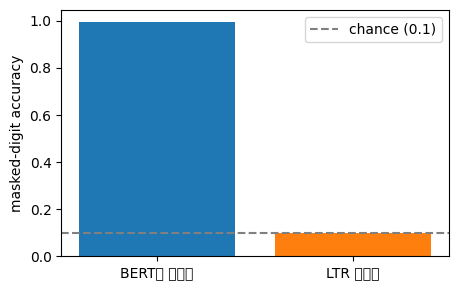

In [19]:
# 두 모델을 같은 데이터, 같은 설정으로 학습합니다. (CPU 기준 모델당 약 20초)
results = {}
for name, causal in [('BERT식 양방향', False), ('LTR 단방향', True)]:
    seed_everything(0)
    model = TinyBERT(VOCAB, causal=causal)
    final_loss = pretrain(model)
    results[name] = eval_middle_acc(model)
    print(f'{name:10s} | 마지막 학습 loss {final_loss:.3f} | 가린 숫자 맞히기 정확도 {results[name]:.3f}')

plt.figure(figsize=(5, 3.2))
plt.bar(list(results), list(results.values()), color=['tab:blue', 'tab:orange'])
plt.axhline(0.1, ls='--', color='gray', label='chance (0.1)')
plt.ylabel('masked-digit accuracy'); plt.legend(); plt.show()

In [20]:
# ✅ 확인 셀: 이 문제는 오른쪽 문맥이 꼭 필요하도록 설계했으므로 아래 결과가 정상입니다.
assert results['BERT식 양방향'] > 0.9, '양방향 모델이 학습되지 않았다면 ⑭, ⑮를 다시 확인하세요.'
assert results['LTR 단방향'] < 0.25, '단방향 모델이 우연 수준(0.1)을 크게 넘으면 ⑭의 마스크를 확인하세요.'
print('✅ 통과')

✅ 통과


**4-3.** 결과를 기록하고 아래 세 가지에 답하세요.

| 모델 | 가린 숫자 맞히기 정확도 |
|---|---|
| BERT식 양방향 | |
| LTR 단방향 | |

(a) 단방향 모델의 정확도가 왜 우연 수준(0.1)에 머무나요?
(b) 논문 Table 5에서 **양방향성만의 효과**를 보려면 어느 두 행을 비교해야 하나요? 그 두 행의 MNLI-m, QNLI, MRPC, SST-2, SQuAD 차이를 계산하세요. (BERT-BASE와 비교하면 안 되는 이유도 쓰세요.)
(c) 이 결과만으로 "양방향이 모든 과제에서 크게 유리하다"고 결론 내려도 되나요?

**답변:**

| 모델 | 가린 숫자 맞히기 정확도 |
|---|---|
| BERT식 양방향 | (실행 결과) |
| LTR 단방향 | (실행 결과) |

**(a)** 가리는 자리($s_2, s_4, s_6, s_8$)는 (왼쪽 이웃 + 오른쪽 이웃) mod 10인데, LTR 모델은 자기 위치까지만 볼 수 있어서 오른쪽 이웃을 못 본다. 오른쪽 이웃($s_3, s_5, \dots$)은 무작위로 뽑은 숫자라 왼쪽 문맥과 독립이니까 왼쪽만 보면 정답이 0~9에 균등하게 퍼져 있음 → 학습을 아무리 해도 1/10 = 0.1이 최대다.

**(b)** 양방향성만의 효과를 보려면 **No NSP vs LTR & No NSP**를 비교해야 한다. 둘 다 NSP 없이 학습해서 차이가 MLM(양방향)이냐 LTR(단방향)이냐 하나뿐이기 때문.

| | MNLI-m | QNLI | MRPC | SST-2 | SQuAD (F1) |
|---|---|---|---|---|---|
| No NSP | 83.9 | 84.9 | 86.5 | 92.6 | 87.9 |
| LTR & No NSP | 82.1 | 84.3 | 77.5 | 92.1 | 77.8 |
| 차이 | +1.8 | +0.6 | +9.0 | +0.5 | +10.1 |

BERT-BASE는 MLM + **NSP**로 학습한 모델이라 LTR & No NSP와 바로 비교하면 양방향 효과랑 NSP 효과가 섞여 버린다. (바뀐 조건이 2개)

**(c)** 안 된다고 생각함.
- 이 toy 문제는 오른쪽 문맥 없이는 못 풀게 일부러 만든 거라 차이가 극단적으로 나온 것.
- Table 5에서도 task마다 차이가 다르다. SQuAD(+10.1), MRPC(+9.0)는 크지만 SST-2(+0.5), QNLI(+0.6)는 작음. 한 문장 감정 분류처럼 왼쪽 문맥만으로도 어느 정도 되는 task는 이득이 작다.
- LTR 모델 위에 BiLSTM을 얹으면 SQuAD가 77.8 → 84.9로 꽤 회복되기도 하고, 우리 실험은 작은 모델 + 합성 데이터 + seed 1개라 이걸로 일반화하긴 무리.

## Part 5. fine-tuning 헤드 만들기 (§3.2, §4.2–4.3)
BERT는 사전학습된 인코더에 **작은 출력층만** 얹어 모든 파라미터를 함께 fine-tuning합니다.

### 문제 5-1. [CLS]로 문장 분류하기
분류 과제에서는 `[CLS]` 위치의 최종 hidden vector $C\in\mathbb R^H$를 분류층 $W\in\mathbb R^{K\times H}$에 넣습니다 (§4.1). 새로 추가되는 파라미터는 이 분류층뿐입니다.

In [21]:
class BertForSequenceClassification(nn.Module):
    def __init__(self, bert, d, n_classes):
        super().__init__()
        self.bert = bert
        self.classifier = nn.Linear(d, n_classes)       # fine-tuning에서 새로 추가되는 파라미터

    def forward(self, ids, segs=None):
        h = self.bert.encode(ids, segs)                  # [B, L, d]
        c = h[:, 0]  # TODO ⑯: [CLS] 위치의 최종 hidden vector C
        return self.classifier(c)

In [22]:
# ✅ 확인 셀
class _Stub(nn.Module):                                  # [CLS]만 클래스 0을, 나머지 위치는 클래스 1을 가리키는 가짜 인코더
    def encode(self, ids, segs=None):
        h = torch.zeros(ids.size(0), ids.size(1), 4)
        h[:, 0] = torch.tensor([5., 1., 0., 0.])
        h[:, 1:] = torch.tensor([0., 100., 0., 0.])
        return h
stub_clf = BertForSequenceClassification(_Stub(), d=4, n_classes=2)
with torch.no_grad():
    stub_clf.classifier.weight.copy_(torch.eye(4)[:2]); stub_clf.classifier.bias.zero_()
assert stub_clf(torch.zeros(3, 6, dtype=torch.long)).argmax(-1).tolist() == [0, 0, 0], '[CLS] 위치만 써야 합니다.'

seed_everything(0)
clf = BertForSequenceClassification(TinyBERT(VOCAB), d=64, n_classes=3)
x = make_toy_batch(4, torch.Generator().manual_seed(0))
logits = clf(x)
assert logits.shape == (4, 3)
F.cross_entropy(logits, torch.tensor([0, 1, 2, 0])).backward()
assert clf.bert.emb.tok.weight.grad.abs().sum() > 0, 'fine-tuning에서는 인코더 파라미터도 함께 학습됩니다.'
n_new = sum(p.numel() for n, p in clf.named_parameters() if n.startswith('classifier'))
print('새로 추가된 파라미터:', n_new)
assert n_new == 64 * 3 + 3
print('✅ [CLS] 분류 헤드 확인')

새로 추가된 파라미터: 195
✅ [CLS] 분류 헤드 확인


### 문제 5-2. SQuAD 구간 예측 헤드 만들기 (§4.2)
질문+지문을 한 시퀀스로 넣고, 새로 추가하는 벡터 시작 $S\in\mathbb R^H$와 **끝 $E\in\mathbb R^H$** 두 개로 각 위치의 점수를 만듭니다. 위치 $i$가 답의 시작일 점수는 $S\cdot T_i$, 위치 $j$가 끝일 점수는 $E\cdot T_j$이고, **$j\ge i$인 구간 중 $S\cdot T_i+E\cdot T_j$가 최대인 구간**을 예측합니다.

### 문제 5-3. SQuAD v2.0의 '답 없음' 처리 (§4.3)
답이 없는 질문은 시작과 끝이 모두 `[CLS]`(위치 0)인 구간으로 봅니다. 답 없음 점수는 $s_\mathrm{null}=S\cdot C+E\cdot C$이고, 최고 비어 있지 않은 구간 점수 $\hat s_{i,j}$가 $s_\mathrm{null}+\tau$보다 클 때만 답이 있다고 예측합니다.

In [23]:
def span_logits(h, S, E):
    # h: [B, L, d] 최종 hidden vector T, S와 E: [d]. 반환: 시작/끝 점수 [B, L]
    start_logits = h @ S  # TODO ⑰: 각 위치의 S·T_i
    end_logits = h @ E  # TODO ⑱: 각 위치의 E·T_j
    return start_logits, end_logits

def best_span(start_logits, end_logits, max_answer_len=30):
    # 한 샘플(1차원 [L])에서 j >= i 이고 S·T_i + E·T_j가 최대인 (i, j)
    L = start_logits.numel()
    score = start_logits[:, None] + end_logits[None, :]                  # score[i, j]
    valid = torch.triu(torch.ones(L, L, dtype=torch.bool))  # TODO ⑲: j >= i인 칸만 True → 대각선 포함 상삼각
    valid &= ~torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=max_answer_len)   # 너무 긴 구간 제외
    i, j = divmod(score.masked_fill(~valid, float('-inf')).argmax().item(), L)
    return i, j

def predict_with_no_answer(start_logits, end_logits, tau=0.0):
    s_null = (start_logits[0] + end_logits[0]).item()  # TODO ⑳: 답 없음 점수 S·C + E·C
    i, j = best_span(start_logits[1:], end_logits[1:])                   # [CLS]를 뺀 나머지에서 최고 구간
    s_best = (start_logits[1:][i] + end_logits[1:][j]).item()
    return (i + 1, j + 1) if s_best > s_null + tau else None

In [24]:
# ✅ 확인 셀
seed_everything(0)
h, S, E = torch.randn(2, 5, 8), torch.randn(8), torch.randn(8)
st, en = span_logits(h, S, E)
assert st.shape == en.shape == (2, 5)
torch.testing.assert_close(st, torch.einsum('bld,d->bl', h, S))
torch.testing.assert_close(en, torch.einsum('bld,d->bl', h, E))

# 시작·끝을 따로 argmax하면 끝이 시작보다 앞서는 잘못된 구간이 나올 수 있습니다.
s1, e1 = torch.tensor([0., 1., 9., 0.]), torch.tensor([8., 0., 1., 0.])
assert (s1.argmax().item(), e1.argmax().item()) == (2, 0)      # 따로 고르면 (2, 0): 잘못된 구간
assert best_span(s1, e1) == (2, 2)                              # j >= i를 지키면 (2, 2)

s2, e2 = torch.tensor([9., 0., 0., 1.]), torch.tensor([1., 2., 0., 9.])
assert best_span(s2, e2) == (0, 3)
assert best_span(s2, e2, max_answer_len=2) == (0, 1)             # 길이 제한을 두면 달라짐

s3, e3 = torch.tensor([5., 0., 0., 0.]), torch.tensor([5., 0., 0., 0.])
assert predict_with_no_answer(s3, e3) is None                    # [CLS] 점수가 압도적이면 답 없음
s4, e4 = torch.tensor([0., 3., 0., 0.]), torch.tensor([0., 0., 4., 0.])
assert predict_with_no_answer(s4, e4) == (1, 2)
assert predict_with_no_answer(s4, e4, tau=10.0) is None          # 임계값 τ를 높이면 답 없음 쪽으로
print('✅ 구간 예측과 답 없음 처리 확인')

✅ 구간 예측과 답 없음 처리 확인


## Part 6. 결과 해석 (코드 없이 논문 §3.2, §5를 근거로 답하세요)

**6-1.** 논문 Table 5에서 BERT-BASE와 "No NSP"를 비교하세요. 그 차이를 과제별로 계산한 뒤, "NSP는 모든 과제에서 성능을 크게 높인다"라고 써도 되는지 판단하세요. 이 과제의 Part 2는 NSP의 효과를 확인해 주었나요?

**답변:**

| | MNLI-m | QNLI | MRPC | SST-2 | SQuAD (F1) |
|---|---|---|---|---|---|
| BERT-BASE | 84.4 | 88.4 | 86.7 | 92.7 | 88.5 |
| No NSP | 83.9 | 84.9 | 86.5 | 92.6 | 87.9 |
| 차이 | +0.5 | +3.5 | +0.2 | +0.1 | +0.6 |

- NSP를 빼면 QNLI는 3.5 떨어져서 꽤 크지만 나머지는 0.1~0.6 정도라 **"모든 과제에서 크게 높인다"는 틀린 표현**이다. 논문 본문은 QNLI, MNLI, SQuAD에서 크게 떨어진다고 했는데, 숫자로 보면 MNLI(0.5), SQuAD(0.6)는 '크게'라고 하기 애매하고 단일 실행 결과라 0.1~0.2 차이는 노이즈일 수도 있다.
- (나중에 나온 RoBERTa에서는 NSP를 빼도 성능이 비슷하거나 오히려 좋아졌다고 함)
- Part 2에서는 NSP **데이터를 만드는 규칙**(IsNext / NotNext 50:50)만 구현해서 확인했고 NSP로 학습하거나 성능을 비교하진 않았으니까, NSP 효과는 확인하지 못했다.

**6-2.** fine-tuning에서 새로 도입되는 파라미터는 분류, SQuAD v1.1, SQuAD v2.0에서 각각 무엇인가요? 그리고 Part 5에서 확인했듯이 fine-tuning은 인코더 파라미터까지 함께 학습합니다. 논문 §5.3의 feature-based 접근과 무엇이 다른지 쓰고, Table 7의 BERT-BASE 결과(fine-tuning과 "Concat Last Four Hidden")를 비교해 그 차이를 해석하세요.

**답변:**

- 새로 추가되는 파라미터
  - 분류: 분류층 가중치 $W \in \mathbb{R}^{K\times H}$ ($K$ = 클래스 수)뿐. `[CLS]`의 최종 hidden $C$에 붙여서 $\mathrm{softmax}(CW^\top)$. (구현에선 bias까지 있어서 Part 5 확인 셀 기준 64×3+3 = 195개)
  - SQuAD v1.1: 시작 벡터 $S \in \mathbb{R}^H$, 끝 벡터 $E \in \mathbb{R}^H$ 두 개
  - SQuAD v2.0: v1.1과 똑같이 $S, E$만 씀. 답 없음은 시작 = 끝 = `[CLS]`인 구간으로 처리하니까 추가 파라미터가 없다. ($\tau$는 dev set에서 고르는 값이지 학습하는 파라미터는 아님)
- feature-based(§5.3)는 BERT 파라미터를 **고정**한 채 몇 개 층의 activation만 뽑아 feature로 쓰고, 그 위에 따로 만든 모델(2층 768차원 BiLSTM + 분류층)만 학습한다. fine-tuning은 출력층만 얹고 **BERT 전체를 같이 업데이트**한다는 게 차이.
- Table 7 (CoNLL-2003 NER, Dev F1): fine-tuning BERT-BASE 96.4 vs Concat Last Four Hidden 96.1 → 0.3 차이밖에 안 난다.
  - BERT 표현 자체에 정보가 이미 많이 들어 있어서 고정 feature로 써도 fine-tuning에 거의 근접한다는 것 → BERT는 두 방식 다 잘 됨. feature-based는 task 전용 구조를 붙이기 쉽고, 표현을 한 번만 계산해 두면 여러 실험을 싸게 돌릴 수 있다는 장점도 있다.
  - 다만 마지막 층 하나만 쓰면 94.9로 더 떨어지니까 feature로 쓸 땐 여러 층을 같이 쓰는 게 중요해 보임.

**6-3.** 이 과제에서 **직접 확인한 사실** 두 가지와, 이 과제만으로는 **확인할 수 없는 논문의 주장** 두 가지를 각각 쓰세요.

**답변:**

- 직접 확인한 사실
  1. 파라미터 수를 직접 세 보면 BASE 109.1M, LARGE 334.6M으로 논문의 110M / 340M과 거의 맞고, 층당 파라미터 수(7,087,872)는 PyTorch `TransformerEncoderLayer`와 정확히 같다.
  2. 오른쪽 문맥이 꼭 필요한 문제에서는 같은 구조·데이터·설정이라도 MLM으로 학습한 양방향 모델만 풀 수 있고, 단방향(LTR) 모델은 우연 수준에 머문다. (causal mask가 있으면 뒤쪽 토큰을 바꿔도 앞쪽 표현이 그대로인 것도 확인)
- 이 과제만으로는 확인할 수 없는 주장
  1. NSP가 QNLI, MNLI, SQuAD 같은 문장 쌍 task 성능에 도움이 된다는 것 (NSP로 학습하거나 비교하지 않았음)
  2. BooksCorpus + Wikipedia로 사전학습한 BERT가 GLUE 80.5, SQuAD v1.1 F1 93.2 같은 실제 SOTA 성능을 낸다는 것, 그리고 모델을 키우면 데이터가 작은 task에서도 성능이 계속 오른다는 것(§5.2)

## 참고 자료
- [BERT 논문](https://arxiv.org/abs/1810.04805): §3, §3.1, §3.2, §4.2–4.3, §5.1–5.3, Table 5–7, 부록 A.1(마스킹 세부), A.4(Figure 3)
- [공식 구현](https://github.com/google-research/bert): 논문 초록에 안내된 코드와 사전학습 모델. 이 과제의 설명용 구현과 세부가 다릅니다.
- [PyTorch TransformerEncoderLayer](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html)

원 논문의 실험 성능을 재현하려면 BooksCorpus·Wikipedia 사전학습과 공식 fine-tuning 설정이 필요합니다. 이 과제는 메커니즘을 확인하는 축소 실습입니다.